# Hotel Search Ranking, Part 1: The Data and Position Bias

**The question behind this project:** when someone searches for a hotel, which hotels should go at the top of the list so that they actually book?

Before building any model I want to understand two things:

1. What the Expedia data really looks like once it's loaded.
2. How much **position bias** there is. In other words, how many of a hotel's clicks come simply from sitting near the top of the page, and how many come from the hotel itself.

The second one matters a lot. Every click in this data was nudged by where Expedia chose to put the hotel. If I train a model on those clicks without thinking about it, the model partly learns "Expedia ranked this high" instead of "people want this hotel".

The good news is that Expedia showed about 30% of searches in **random order**. In those searches a hotel's spot on the page has nothing to do with how good it is, so they let me pull apart the effect of position from the effect of the hotel.

Dataset: [Personalize Expedia Hotel Searches, ICDM 2013 (Kaggle)](https://www.kaggle.com/c/expedia-personalized-sort)

Author: Siddharth Suman

## Setup

I downloaded the training file from Kaggle and keep it in my Google Drive. The full file has about 10 million rows, which is heavy for free Colab, so the first run keeps every 4th search (around 100,000 searches) and saves that smaller sample back to Drive. Every run after that loads the sample in a few seconds.

In [1]:
import os
import glob
import zipfile
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/expedia-hotel-ranking'
    IN_COLAB = True
except ImportError:
    WORK_DIR = 'data'
    IN_COLAB = False

RAW_DIR = '/content/expedia_raw' if IN_COLAB else 'data/raw'
for folder in [WORK_DIR, RAW_DIR, 'images']:
    os.makedirs(folder, exist_ok=True)

SAMPLE_PATH = os.path.join(WORK_DIR, 'train_sample.parquet')
print("Sample already saved:", os.path.exists(SAMPLE_PATH))

Mounted at /content/drive
Sample already saved: False


In [2]:
# The Kaggle training file sits in my Google Drive.
# This is the ID from its share link (the long code between /d/ and /view).
DRIVE_FILE_ID = '1NM5WDSkgi6xEvmo9Pp7UKvkbx2A1BeQn'

def copy_from_my_drive(file_id):
    # Copies one file from my Drive into Colab, using my own Google login
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    service = build('drive', 'v3')
    info = service.files().get(fileId=file_id, fields='name, size').execute()
    target = os.path.join(RAW_DIR, info['name'])
    print(f"Copying {info['name']} ({int(info.get('size', 0)) / 1e9:.1f} GB) into Colab")

    request = service.files().get_media(fileId=file_id)
    with open(target, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request, chunksize=200 * 1024 * 1024)
        done = False
        while not done:
            status, done = downloader.next_chunk()
            print(f"  {int(status.progress() * 100)}% done")
    return target

def unzip(z):
    print("Unzipping", os.path.basename(z))
    try:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(RAW_DIR)
    except NotImplementedError:
        # Kaggle packed data.zip with Deflate64, which Python's own zip reader can't open.
        # The standard unzip tool that comes with Colab can.
        subprocess.run(['unzip', '-o', '-q', z, '-d', RAW_DIR], check=True)

def find_train_csv(path):
    # Works whether I'm given train.csv itself, a zip, or a folder with zips inside
    if os.path.isfile(path) and zipfile.is_zipfile(path):
        unzip(path)
        path = RAW_DIR
    if os.path.isfile(path):
        return path
    done = set()
    for _ in range(3):
        hits = [h for h in glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)
                if os.path.basename(h).lower().startswith('train')]
        if hits:
            return hits[0]
        # The benchmark zips are Kaggle's example submissions, not data
        inner = [z for z in glob.glob(os.path.join(path, '**', '*.zip'), recursive=True)
                 if 'benchmark' not in os.path.basename(z).lower() and z not in done]
        if not inner:
            return None
        for z in inner:
            unzip(z)
            done.add(z)
        path = RAW_DIR
    return None

if not os.path.exists(SAMPLE_PATH):
    train_csv = find_train_csv(WORK_DIR)
    if train_csv is None and IN_COLAB:
        train_csv = find_train_csv(copy_from_my_drive(DRIVE_FILE_ID))
    if train_csv is None:
        train_csv = 'data/train.csv'
    print("Reading", train_csv)

    # I keep every 4th search. Whole searches, not random rows, because a ranking
    # only makes sense when I have every hotel that was shown for that search.
    # Missing values in this file are written as the word NULL.
    parts = []
    for chunk in pd.read_csv(train_csv, na_values=['NULL'], chunksize=1_000_000):
        parts.append(chunk[chunk['srch_id'] % 4 == 0])
    df = pd.concat(parts, ignore_index=True)

    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

    df.to_parquet(SAMPLE_PATH, index=False)
    print("Saved sample to Drive")

df = pd.read_parquet(SAMPLE_PATH)
print(f"{len(df):,} rows, {df['srch_id'].nunique():,} searches, {df['prop_id'].nunique():,} hotels")
df.head()

Unzipping expedia-personalized-sort.zip
Unzipping data.zip
Reading /content/expedia_raw/train.csv
Saved sample to Drive
2,478,444 rows, 99,817 searches, 118,451 hotels


,srch_id,date_time,site_id,visitor_location_country_id,visitor_hist_starrating,visitor_hist_adr_usd,prop_country_id,prop_id,prop_starrating,prop_review_score,prop_brand_bool,prop_location_score1,prop_location_score2,prop_log_historical_price,position,price_usd,promotion_flag,srch_destination_id,srch_length_of_stay,srch_booking_window,srch_adults_count,srch_children_count,srch_room_count,srch_saturday_night_bool,srch_query_affinity_score,orig_destination_distance,random_bool,comp1_rate,comp1_inv,comp1_rate_percent_diff,comp2_rate,comp2_inv,comp2_rate_percent_diff,comp3_rate,comp3_inv,comp3_rate_percent_diff,comp4_rate,comp4_inv,comp4_rate_percent_diff,comp5_rate,comp5_inv,comp5_rate_percent_diff,comp6_rate,comp6_inv,comp6_rate_percent_diff,comp7_rate,comp7_inv,comp7_rate_percent_diff,comp8_rate,comp8_inv,comp8_rate_percent_diff,click_bool,gross_bookings_usd,booking_bool
0,4,2012-12-31 08:59:22,5,219,NaN,NaN,219,3625,4,4.0,0,3.22,0.2544,5.98,21,295.0,0,12588,2,46,1,0,1,1,NaN,238.350006,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
1,4,2012-12-31 08:59:22,5,219,NaN,NaN,219,11622,4,4.0,0,2.71,NaN,5.64,36,299.0,0,12588,2,46,1,0,1,1,NaN,238.339996,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
2,4,2012-12-31 08:59:22,5,219,NaN,NaN,219,11826,5,4.5,1,3.22,0.1924,6.10,22,373.0,1,12588,2,46,1,0,1,1,NaN,238.330002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
3,4,2012-12-31 08:59:22,5,219,NaN,NaN,219,22824,3,4.0,0,3.26,0.3729,5.74,4,329.0,0,12588,2,46,1,0,1,1,NaN,238.289993,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
4,4,2012-12-31 08:59:22,5,219,NaN,NaN,219,37581,5,4.5,0,3.09,0.2508,6.21,26,600.0,0,12588,2,46,1,0,1,1,NaN,238.350006,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0


## First look

Each row is one hotel shown in one search. The columns that matter most for now:

* `srch_id`: which search the row belongs to
* `position`: where the hotel appeared on the results page (1 is the top)
* `random_bool`: 1 if that search was shown in random order
* `click_bool` and `booking_bool`: whether the user clicked the hotel, and whether they booked it
* `price_usd`, `prop_starrating`, `prop_review_score`, `prop_location_score2`: what the user could see, or what describes the hotel

In [3]:
searches = df.groupby('srch_id').agg(
    hotels_shown=('prop_id', 'size'),
    clicks=('click_bool', 'sum'),
    booked=('booking_bool', 'max'),
    random_order=('random_bool', 'first'),
)

print(f"Hotels shown per search: median {searches['hotels_shown'].median():.0f}, max {searches['hotels_shown'].max()}")
print(f"Click rate per hotel shown: {df['click_bool'].mean():.2%}")
print(f"Booking rate per hotel shown: {df['booking_bool'].mean():.2%}")
print(f"Searches ending in a booking: {searches['booked'].mean():.1%}")
print(f"Searches shown in random order: {searches['random_order'].mean():.1%}")

print("\nSearches ending in a booking, by how the list was ordered:")
print(searches.groupby('random_order')['booked'].mean()
      .rename({0: 'Expedia order', 1: 'Random order'}).map('{:.1%}'.format))

Hotels shown per search: median 29, max 38
Click rate per hotel shown: 4.47%
Booking rate per hotel shown: 2.79%
Searches ending in a booking: 69.3%
Searches shown in random order: 30.4%

Searches ending in a booking, by how the list was ordered:
random_order
Expedia order    93.9%
Random order     13.0%
Name: booked, dtype: object


### What this tells me

Clicks and bookings are rare. Only 4.5% of the hotels shown get a click, and 2.8% get booked. Most rows are simply a hotel that was shown and ignored. A model could look very "accurate" by predicting that nothing happens every time, so accuracy is no use here. What matters is whether the hotel the person actually wanted ends up near the top, and that's what NDCG measures.

The booking split looked dramatic at first: 93.9% of searches in Expedia's order ended in a booking, against 13.0% of searches in random order. I nearly wrote that up as the value of good ranking. It isn't, or at least not all of it. Shuffling a list can't turn a 94% booking rate into 13% on its own. The gap most likely comes from how searches were picked for this dataset: nearly every normal search that made it in ended with a booking, while the random ones were kept whether anyone booked or not. Published work on this same data puts bookings in random searches at around 8%, so my 13% is in the right range.

The lesson I'm taking: before comparing two groups, check how each one got into the data. For the position analysis below I lean mainly on the random searches, where this problem doesn't come up.

## Data quirks to sort out before modelling

In [4]:
key_cols = ['price_usd', 'prop_starrating', 'prop_review_score', 'prop_location_score1',
            'prop_location_score2', 'prop_log_historical_price', 'orig_destination_distance',
            'visitor_hist_starrating', 'visitor_hist_adr_usd', 'srch_query_affinity_score']
missing = df[key_cols].isna().mean().sort_values(ascending=False)
print("Share missing:")
print(missing.map('{:.0%}'.format))

print("\nprice_usd percentiles:")
print(df['price_usd'].quantile([0.01, 0.25, 0.5, 0.75, 0.99, 1.0]).round(0))

# A star rating or review score of 0 isn't a real score. It means "no rating yet".
print(f"\nHotels with star rating 0: {(df['prop_starrating'] == 0).mean():.1%}")
print(f"Hotels with review score 0: {(df['prop_review_score'] == 0).mean():.1%}")

Share missing:
visitor_hist_starrating      95%
visitor_hist_adr_usd         95%
srch_query_affinity_score    94%
orig_destination_distance    32%
prop_location_score2         22%
prop_review_score             0%
prop_starrating               0%
price_usd                     0%
prop_log_historical_price     0%
prop_location_score1          0%
dtype: object

price_usd percentiles:
0.01         34.0
0.25         85.0
0.50        122.0
0.75        185.0
0.99        599.0
1.00    9661340.0
Name: price_usd, dtype: float64

Hotels with star rating 0: 3.4%
Hotels with review score 0: 4.7%


### What this tells me

The columns about the visitor's own history (their usual star rating and usual spend) are missing for 95% of rows, and the query affinity score for 94%. Most people searching weren't logged in or had no booking history. I'll keep these only as a flag for "do we know this person or not", not as numbers to lean on.

Distance to the hotel is missing for 32% of rows and `prop_location_score2` for 22%. For those I'll fill gaps within each destination rather than with one global value, because a missing location score in central Paris and one in a ski village shouldn't get the same guess.

Price needs the most care. The median is $122 and 99% of prices sit under $599, which looks like normal nightly rates. But the highest value is over $9.6 million, which is clearly not a hotel room. Expedia's own notes also say `price_usd` can be per night in some countries and for the whole stay in others, with taxes handled differently. So I'll drop the absurd values and, more importantly, compare each hotel's price with the other hotels **in the same search**, for example its price rank within the list. That's also how a guest sees price: cheap or expensive compared with what else is on the screen.

Star ratings of 0 (3.4% of hotels) and review scores of 0 (4.7%) mean "not rated yet". I'll treat them as missing, not as the worst possible score. From my years in hotels, an unrated property is usually a new or small one, not a bad one.

## Position bias: how much does being near the top matter?

For each position on the page I work out the click rate, separately for searches in Expedia's own order and searches in random order.

* In **Expedia order**, the top hotels get more clicks for two reasons: they sit at the top, *and* Expedia put good hotels there.
* In **random order**, hotels land wherever chance puts them. Any drop in clicks further down the page there comes from position alone.

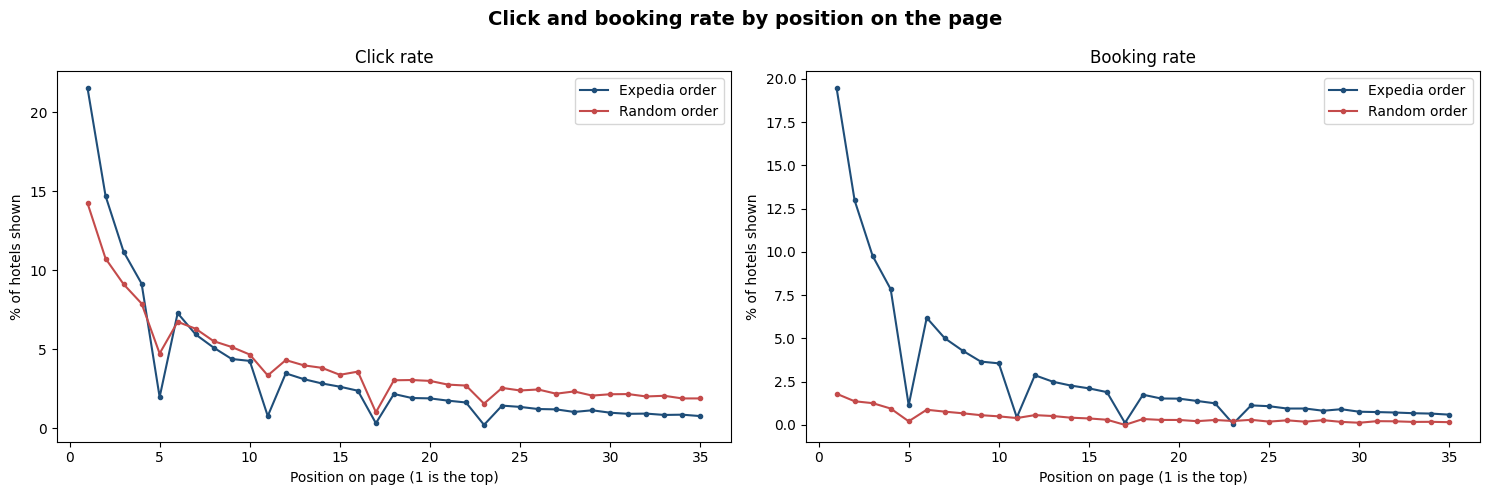

In [5]:
df['ordering'] = np.where(df['random_bool'] == 1, 'Random order', 'Expedia order')

by_pos = (df.groupby(['ordering', 'position'])
            .agg(click_rate=('click_bool', 'mean'),
                 booking_rate=('booking_bool', 'mean'),
                 rows=('click_bool', 'size'))
            .reset_index())

# Positions far down the page have few rows, so I stop at 35
by_pos = by_pos[by_pos['position'] <= 35]

colors = {'Expedia order': '#1F4E79', 'Random order': '#C44B4B'}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Click and booking rate by position on the page', fontsize=14, fontweight='bold')

for name, grp in by_pos.groupby('ordering'):
    axes[0].plot(grp['position'], grp['click_rate'] * 100, marker='o', markersize=3,
                 color=colors[name], label=name)
    axes[1].plot(grp['position'], grp['booking_rate'] * 100, marker='o', markersize=3,
                 color=colors[name], label=name)

axes[0].set_title('Click rate')
axes[1].set_title('Booking rate')
for ax in axes:
    ax.set_xlabel('Position on page (1 is the top)')
    ax.set_ylabel('% of hotels shown')
    ax.legend()

plt.tight_layout()
plt.savefig('images/01_position_bias.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Putting numbers on it. Random order searches show the effect of position by itself.
rnd = df[df['random_bool'] == 1]
top = rnd[rnd['position'] <= 5]['click_bool'].mean()
mid = rnd[rnd['position'].between(11, 25)]['click_bool'].mean()
print(f"Random order, click rate at positions 1 to 5:   {top:.2%}")
print(f"Random order, click rate at positions 11 to 25: {mid:.2%}")
print(f"Top 5 instead of the middle: {top / mid:.1f}x the clicks, from position alone")

exp = df[df['random_bool'] == 0]
exp_top = exp[exp['position'] <= 5]['click_bool'].mean()
print(f"\nExpedia order, click rate at positions 1 to 5: {exp_top:.2%}")
print(f"Top 5 in Expedia order compared with top 5 in random order: {exp_top / top:.1f}x")

Random order, click rate at positions 1 to 5:   10.49%
Random order, click rate at positions 11 to 25: 3.27%
Top 5 instead of the middle: 3.2x the clicks, from position alone

Expedia order, click rate at positions 1 to 5: 14.02%
Top 5 in Expedia order compared with top 5 in random order: 1.3x


### What this tells me

Position matters a lot, even when it has nothing to do with the hotel. In random order, hotels in the top 5 get clicked 10.5% of the time, against 3.3% for positions 11 to 25. That's **3.2 times the clicks just for being near the top**. Nothing about those hotels is better; they're simply easier to see. So a click is partly a vote for the hotel and partly a vote for its spot on the screen.

In Expedia's own order the top 5 do even better, at 14.0%, or 1.3 times the random top 5. That extra lift is the part that comes from Expedia putting genuinely attractive hotels up there. It's real, but it's much smaller than the effect of position itself.

Two more things stand out in the chart. From about position 6 onwards, the random line sits *above* Expedia's line. That makes sense once you think about it: Expedia moves its strongest hotels to the top, so what's left lower down its list is weaker than a random draw. There are also sharp dips at positions 5, 11, 17 and 23, every sixth slot, in both kinds of search. Since it happens in random order too, it's about the page layout, not the hotels. My guess is that something else, maybe a different type of listing, filled those slots on the page. I can't tell from the data, so I'll just keep it in mind.

For the model this gives one simple rule: `position` can't be a feature. It describes what Expedia did, not what the guest wants, and a new search doesn't have a position yet.

## Clicks against bookings: does position tempt people into clicking?

If a high spot on the page pulls in clicks from people who aren't that interested, those clicks should turn into bookings **less** often than clicks further down. To check, I look only at clicked hotels in searches shown in random order, and ask what share of those clicks became a booking at each part of the page.

                clicks booked_after_click
position_group                           
1 to 5           12694                13%
6 to 10           8183                12%
11 to 15          4043                12%
16 to 20          3004                 9%
21 to 25          2247                 9%
26+               3894                 9%


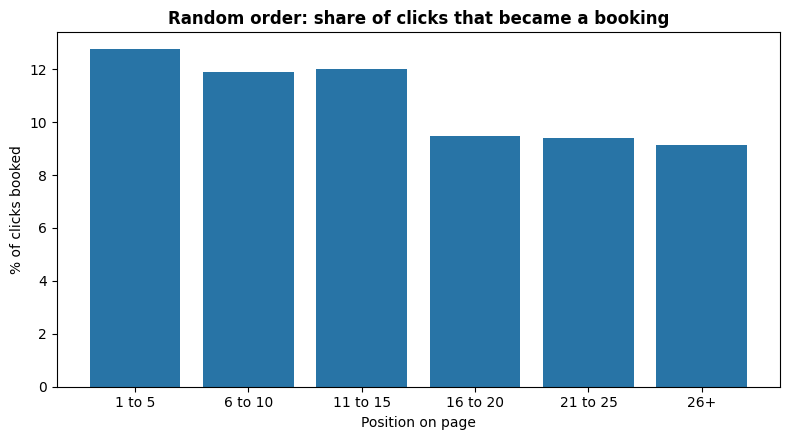

In [7]:
clicked = rnd[rnd['click_bool'] == 1].copy()
clicked['position_group'] = pd.cut(clicked['position'], bins=[0, 5, 10, 15, 20, 25, 40],
                                   labels=['1 to 5', '6 to 10', '11 to 15', '16 to 20', '21 to 25', '26+'])

conversion = (clicked.groupby('position_group', observed=True)
                     .agg(clicks=('click_bool', 'size'),
                          booked_after_click=('booking_bool', 'mean')))
print(conversion.assign(booked_after_click=conversion['booked_after_click'].map('{:.0%}'.format)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(conversion.index.astype(str), conversion['booked_after_click'] * 100, color='#2874A6')
ax.set_title('Random order: share of clicks that became a booking', fontweight='bold')
ax.set_xlabel('Position on page')
ax.set_ylabel('% of clicks booked')
plt.tight_layout()
plt.savefig('images/01_booking_after_click.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells me

This is where the data proved me wrong. I expected clicks near the top to be "cheap", with people tapping the first results out of habit and then not booking. The random searches show the opposite: **13% of clicks in the top 5 turned into a booking, against about 9% for clicks beyond position 15.**

Thinking about it as someone who has watched guests choose rooms, it fits. People tend to book one of the first few places they look at seriously. Someone still clicking at position 25 is usually a browser who opens lots of hotels and books one of them, or none. So top clicks aren't fake. What position really decides is **which hotels get looked at in the first place**.

That changes how I'll treat clicks. A hotel that Expedia often placed at the top will have collected lots of clicks partly because of where it sat. If I build a "popularity" feature from raw click counts, I'm partly copying Expedia's old ranking back into my model. The fairer way is to measure popularity from bookings, or from the random searches where every hotel had the same chance.

## What I'm taking into the next notebook

* **No `position` as a feature.** It reflects Expedia's old ranking, not what the guest wants, and a new search doesn't have one.
* **Bookings count far more than clicks.** I'll train and score with the competition's 5 for a booking, 1 for a click and 0 for nothing.
* **Price only makes sense inside its own search.** I'll remove the absurd prices and build features like price rank and price compared with the search average.
* **Careful with click based popularity.** Clicks in Expedia's order are inflated by position, so hotel popularity should come from bookings or from random searches.
* **Random searches are my fairest test.** Position there has nothing to do with quality, so they show most clearly whether the model finds the hotels people want.